## Specified Signal

In [2]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import warnings
import glob
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print("✅ Libraries imported successfully")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

✅ Libraries imported successfully
Pandas version: 2.3.2
NumPy version: 2.2.6


In [3]:
files = glob.glob("/Users/mac/Desktop/Upwork/GoldSignalGenerator/Artifacts/MinutelyData/XAU-USD_Minute_*.csv")
df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

In [4]:
df["UTC"] = pd.to_datetime(
    df["UTC"], 
    format="%d.%m.%Y %H:%M:%S.%f UTC"
)

df = df.sort_values("UTC", ascending=False).reset_index(drop=True)
df.rename(columns={'UTC':'datetime'}, inplace=True)

In [5]:
print("Data Shape:", df.shape)
print("\n" + "="*60)
print("Data Info:")
print("="*60)
df.info()

print("\n" + "="*60)
print("First 5 rows:")
print("="*60)
print(df.head())

print("\n" + "="*60)
print("Last 5 rows:")
print("="*60)
print(df.tail())

print("\n" + "="*60)
print("Basic Statistics:")
print("="*60)
print(df.describe())

print("\n" + "="*60)
print("Missing Values:")
print("="*60)
print(df.isnull().sum())

Data Shape: (42039, 6)

Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42039 entries, 0 to 42038
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   datetime  42039 non-null  datetime64[ns]
 1   Open      42039 non-null  float64       
 2   High      42039 non-null  float64       
 3   Low       42039 non-null  float64       
 4   Close     42039 non-null  float64       
 5   Volume    42039 non-null  float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 1.9 MB

First 5 rows:
             datetime      Open      High       Low     Close   Volume
0 2025-10-01 13:11:00  3873.145  3873.835  3869.325  3869.715  0.08190
1 2025-10-01 13:10:00  3872.425  3873.538  3872.225  3873.195  0.05479
2 2025-10-01 13:09:00  3869.435  3872.395  3869.395  3872.395  0.05733
3 2025-10-01 13:08:00  3868.695  3869.605  3867.735  3869.565  0.06543
4 2025-10-01 13:07:00  3867.258  3869.498  3867.258  3868.59

In [6]:
df = df.sort_values('datetime').reset_index(drop=True)

print("✅ Data sorted chronologically")
print(f"\nDate range: {df['datetime'].min()} to {df['datetime'].max()}")
print(f"Total duration: {df['datetime'].max() - df['datetime'].min()}")
print(f"Total data points: {len(df)}")

# Extract time-based features
df['hour'] = df['datetime'].dt.hour
df['day_of_week'] = df['datetime'].dt.dayofweek  # Monday=0, Sunday=6
df['day'] = df['datetime'].dt.day
df['month'] = df['datetime'].dt.month

print("\n" + "="*60)
print("Data after sorting (first 5 rows):")
print("="*60)
print(df.head())

print("\n" + "="*60)
print("Data after sorting (last 5 rows):")
print("="*60)
print(df.tail())

print("\n" + "="*60)
print("Time features distribution:")
print("="*60)
print(f"Hours covered: {sorted(df['hour'].unique())}")
print(f"Days of week: {sorted(df['day_of_week'].unique())}")

✅ Data sorted chronologically

Date range: 2025-08-20 00:00:00 to 2025-10-01 13:11:00
Total duration: 42 days 13:11:00
Total data points: 42039

Data after sorting (first 5 rows):
             datetime      Open      High       Low     Close   Volume  hour  \
0 2025-08-20 00:00:00  3313.935  3315.355  3313.815  3315.285  0.02226     0   
1 2025-08-20 00:01:00  3315.205  3315.405  3314.955  3315.205  0.01476     0   
2 2025-08-20 00:02:00  3315.205  3315.205  3313.985  3313.985  0.01206     0   
3 2025-08-20 00:03:00  3313.955  3314.465  3313.459  3314.105  0.02283     0   
4 2025-08-20 00:04:00  3314.125  3314.215  3313.245  3313.615  0.01428     0   

   day_of_week  day  month  
0            2   20      8  
1            2   20      8  
2            2   20      8  
3            2   20      8  
4            2   20      8  

Data after sorting (last 5 rows):
                 datetime      Open      High       Low     Close   Volume  \
42034 2025-10-01 13:07:00  3867.258  3869.498  3867.

In [7]:
def calculate_technical_indicators(df):
    """
    Calculate technical indicators using simple pandas operations
    """
    df = df.copy()
    
    print("Calculating technical indicators...")
    
    # 1. Simple Moving Averages (SMA)
    df['SMA_5'] = df['Close'].rolling(window=5).mean()
    df['SMA_10'] = df['Close'].rolling(window=10).mean()
    df['SMA_20'] = df['Close'].rolling(window=20).mean()
    df['SMA_50'] = df['Close'].rolling(window=50).mean()
    
    # 2. Exponential Moving Averages (EMA)
    df['EMA_5'] = df['Close'].ewm(span=5, adjust=False).mean()
    df['EMA_10'] = df['Close'].ewm(span=10, adjust=False).mean()
    df['EMA_20'] = df['Close'].ewm(span=20, adjust=False).mean()
    
    # 3. RSI (Relative Strength Index)
    delta = df['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
    rs = gain / loss
    df['RSI'] = 100 - (100 / (1 + rs))
    
    # 4. MACD (Moving Average Convergence Divergence)
    ema_12 = df['Close'].ewm(span=12, adjust=False).mean()
    ema_26 = df['Close'].ewm(span=26, adjust=False).mean()
    df['MACD'] = ema_12 - ema_26
    df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
    df['MACD_Histogram'] = df['MACD'] - df['MACD_Signal']
    
    # 5. Bollinger Bands
    df['BB_Middle'] = df['Close'].rolling(window=20).mean()
    bb_std = df['Close'].rolling(window=20).std()
    df['BB_Upper'] = df['BB_Middle'] + (bb_std * 2)
    df['BB_Lower'] = df['BB_Middle'] - (bb_std * 2)
    
    # 6. ATR (Average True Range) - for Stop Loss calculation
    high_low = df['High'] - df['Low']
    high_close = abs(df['High'] - df['Close'].shift())
    low_close = abs(df['Low'] - df['Close'].shift())
    tr = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1)
    df['ATR'] = tr.rolling(window=14).mean()
    
    # 7. Price momentum
    df['Momentum'] = df['Close'] - df['Close'].shift(10)
    df['ROC'] = ((df['Close'] - df['Close'].shift(10)) / df['Close'].shift(10)) * 100
    
    # 8. Volume indicators
    df['Volume_SMA'] = df['Volume'].rolling(window=20).mean()
    df['Volume_Ratio'] = df['Volume'] / df['Volume_SMA']
    
    print("✅ Technical indicators calculated successfully!")
    return df

# Apply the function
df = calculate_technical_indicators(df)

# Check results
print("\n" + "="*60)
print("DataFrame shape after adding indicators:", df.shape)
print("\n" + "="*60)
print("New columns added:")
print("="*60)
new_columns = [col for col in df.columns if col not in ['datetime', 'Open', 'High', 'Low', 'Close', 'Volume', 'hour', 'day_of_week', 'day', 'month']]
print(new_columns)

print("\n" + "="*60)
print("Sample data with indicators (last 5 rows):")
print("="*60)
print(df[['datetime', 'Close', 'RSI', 'MACD', 'ATR']].tail())

print("\n" + "="*60)
print("Missing values after indicator calculation:")
print("="*60)
print(df.isnull().sum())

Calculating technical indicators...
✅ Technical indicators calculated successfully!

DataFrame shape after adding indicators: (42039, 29)

New columns added:
['SMA_5', 'SMA_10', 'SMA_20', 'SMA_50', 'EMA_5', 'EMA_10', 'EMA_20', 'RSI', 'MACD', 'MACD_Signal', 'MACD_Histogram', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'ATR', 'Momentum', 'ROC', 'Volume_SMA', 'Volume_Ratio']

Sample data with indicators (last 5 rows):
                 datetime     Close        RSI      MACD       ATR
42034 2025-10-01 13:07:00  3868.598  44.578165 -1.833034  2.241929
42035 2025-10-01 13:08:00  3869.565  46.420048 -1.663981  2.254071
42036 2025-10-01 13:09:00  3872.395  65.413070 -1.286814  2.146929
42037 2025-10-01 13:10:00  3873.195  73.141026 -0.912831  2.058571
42038 2025-10-01 13:11:00  3869.715  59.158679 -0.887028  2.198571

Missing values after indicator calculation:
datetime           0
Open               0
High               0
Low                0
Close              0
Volume             0
hour           

In [8]:
def create_target_variable(df, future_periods=15, profit_threshold=0.0005):
    """
    Create target variable based on future price movement
    
    Parameters:
    - future_periods: How many minutes ahead to look (15 min = good for 1-min data)
    - profit_threshold: Minimum price movement to consider (0.05% = 0.0005)
    
    Returns:
    - 1 = BUY signal (price will go up)
    - 0 = HOLD (no clear direction)
    - -1 = SELL signal (price will go down)
    """
    df = df.copy()
    
    # Calculate future price change
    df['Future_Close'] = df['Close'].shift(-future_periods)
    df['Future_Return'] = (df['Future_Close'] - df['Close']) / df['Close']
    
    # Create target based on threshold
    def classify_signal(return_val):
        if pd.isna(return_val):
            return np.nan
        elif return_val > profit_threshold:
            return 1  # BUY
        elif return_val < -profit_threshold:
            return -1  # SELL
        else:
            return 0  # HOLD
    
    df['Target'] = df['Future_Return'].apply(classify_signal)
    
    return df

# Create target variable
df = create_target_variable(df, future_periods=15, profit_threshold=0.0005)

print("✅ Target variable created!")
print("\n" + "="*60)
print("Target Distribution:")
print("="*60)
target_counts = df['Target'].value_counts().sort_index()
print(target_counts)
print("\nPercentages:")
print(df['Target'].value_counts(normalize=True).sort_index() * 100)

print("\n" + "="*60)
print("Sample data with target:")
print("="*60)
print(df[['datetime', 'Close', 'Future_Close', 'Future_Return', 'Target']].tail(20))

print("\n" + "="*60)
print("Missing values in target:")
print("="*60)
print(f"Target NaN count: {df['Target'].isna().sum()}")

✅ Target variable created!

Target Distribution:
Target
-1.0     8362
 0.0    23494
 1.0    10168
Name: count, dtype: int64

Percentages:
Target
-1.0    19.898153
 0.0    55.906149
 1.0    24.195698
Name: proportion, dtype: float64

Sample data with target:
                 datetime     Close  Future_Close  Future_Return  Target
42019 2025-10-01 12:52:00  3870.965      3868.598      -0.000611    -1.0
42020 2025-10-01 12:53:00  3870.355      3869.565      -0.000204     0.0
42021 2025-10-01 12:54:00  3870.765      3872.395       0.000421     0.0
42022 2025-10-01 12:55:00  3867.395      3873.195       0.001500     1.0
42023 2025-10-01 12:56:00  3865.975      3869.715       0.000967     1.0
42024 2025-10-01 12:57:00  3866.275           NaN            NaN     NaN
42025 2025-10-01 12:58:00  3869.325           NaN            NaN     NaN
42026 2025-10-01 12:59:00  3870.295           NaN            NaN     NaN
42027 2025-10-01 13:00:00  3870.625           NaN            NaN     NaN
42028 2025-1

In [9]:
# Remove rows with NaN values (from indicators and target)
df_clean = df.dropna().copy()

print(f"Original data: {len(df)} rows")
print(f"After removing NaN: {len(df_clean)} rows")
print(f"Rows removed: {len(df) - len(df_clean)}")

print("\n" + "="*60)
print("Clean data info:")
print("="*60)
print(f"Date range: {df_clean['datetime'].min()} to {df_clean['datetime'].max()}")
print(f"Shape: {df_clean.shape}")

# Define feature columns (excluding target and helper columns)
exclude_cols = ['datetime', 'Target', 'Future_Close', 'Future_Return']
feature_cols = [col for col in df_clean.columns if col not in exclude_cols]

print("\n" + "="*60)
print(f"Total features available: {len(feature_cols)}")
print("="*60)
print("Feature columns:")
for i, col in enumerate(feature_cols, 1):
    print(f"{i}. {col}")

# Check target distribution in clean data
print("\n" + "="*60)
print("Target Distribution in Clean Data:")
print("="*60)
target_counts = df_clean['Target'].value_counts().sort_index()
print(target_counts)
print("\nPercentages:")
print((df_clean['Target'].value_counts(normalize=True).sort_index() * 100).round(2))

# Verify no missing values
print("\n" + "="*60)
print("Missing values check:")
print("="*60)
missing = df_clean.isnull().sum()
print(f"Total missing values: {missing.sum()}")

print("\n✅ Data is clean and ready for modeling!")

Original data: 42039 rows
After removing NaN: 41975 rows
Rows removed: 64

Clean data info:
Date range: 2025-08-20 00:49:00 to 2025-10-01 12:56:00
Shape: (41975, 32)

Total features available: 28
Feature columns:
1. Open
2. High
3. Low
4. Close
5. Volume
6. hour
7. day_of_week
8. day
9. month
10. SMA_5
11. SMA_10
12. SMA_20
13. SMA_50
14. EMA_5
15. EMA_10
16. EMA_20
17. RSI
18. MACD
19. MACD_Signal
20. MACD_Histogram
21. BB_Middle
22. BB_Upper
23. BB_Lower
24. ATR
25. Momentum
26. ROC
27. Volume_SMA
28. Volume_Ratio

Target Distribution in Clean Data:
Target
-1.0     8361
 0.0    23458
 1.0    10156
Name: count, dtype: int64

Percentages:
Target
-1.0    19.92
 0.0    55.89
 1.0    24.20
Name: proportion, dtype: float64

Missing values check:
Total missing values: 0

✅ Data is clean and ready for modeling!


In [10]:
from sklearn.preprocessing import StandardScaler

# For time series, we split chronologically (not randomly!)
# Use 80% for training, 20% for testing
split_index = int(len(df_clean) * 0.8)

train_data = df_clean.iloc[:split_index].copy()
test_data = df_clean.iloc[split_index:].copy()

print("="*60)
print("Data Split:")
print("="*60)
print(f"Total data: {len(df_clean)} rows")
print(f"Training data: {len(train_data)} rows ({len(train_data)/len(df_clean)*100:.1f}%)")
print(f"Testing data: {len(test_data)} rows ({len(test_data)/len(df_clean)*100:.1f}%)")

print(f"\nTraining period: {train_data['datetime'].min()} to {train_data['datetime'].max()}")
print(f"Testing period: {test_data['datetime'].min()} to {test_data['datetime'].max()}")

# Prepare X (features) and y (target)
X_train = train_data[feature_cols]
y_train = train_data['Target']

X_test = test_data[feature_cols]
y_test = test_data['Target']

print("\n" + "="*60)
print("Features and Target:")
print("="*60)
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

# Check target distribution in train/test
print("\n" + "="*60)
print("Target Distribution in Training Set:")
print("="*60)
print(y_train.value_counts().sort_index())
print("\nPercentages:")
print((y_train.value_counts(normalize=True).sort_index() * 100).round(2))

print("\n" + "="*60)
print("Target Distribution in Test Set:")
print("="*60)
print(y_test.value_counts().sort_index())
print("\nPercentages:")
print((y_test.value_counts(normalize=True).sort_index() * 100).round(2))

# Scale the features (important for ML models)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\n" + "="*60)
print("Feature Scaling:")
print("="*60)
print("✅ Features scaled using StandardScaler")
print(f"Scaled X_train shape: {X_train_scaled.shape}")
print(f"Scaled X_test shape: {X_test_scaled.shape}")

print("\n✅ Data is ready for model training!")

Data Split:
Total data: 41975 rows
Training data: 33580 rows (80.0%)
Testing data: 8395 rows (20.0%)

Training period: 2025-08-20 00:49:00 to 2025-09-23 11:01:00
Testing period: 2025-09-23 11:02:00 to 2025-10-01 12:56:00

Features and Target:
X_train shape: (33580, 28)
y_train shape: (33580,)
X_test shape: (8395, 28)
y_test shape: (8395,)

Target Distribution in Training Set:
Target
-1.0     6198
 0.0    19719
 1.0     7663
Name: count, dtype: int64

Percentages:
Target
-1.0    18.46
 0.0    58.72
 1.0    22.82
Name: proportion, dtype: float64

Target Distribution in Test Set:
Target
-1.0    2163
 0.0    3739
 1.0    2493
Name: count, dtype: int64

Percentages:
Target
-1.0    25.77
 0.0    44.54
 1.0    29.70
Name: proportion, dtype: float64

Feature Scaling:
✅ Features scaled using StandardScaler
Scaled X_train shape: (33580, 28)
Scaled X_test shape: (8395, 28)

✅ Data is ready for model training!


In [11]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import time

print("="*60)
print("Training Machine Learning Models...")
print("="*60)

# Dictionary to store models and their performance
models = {}
results = {}

# Model 1: Random Forest
print("\n1️⃣ Training Random Forest Classifier...")
start_time = time.time()
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_scaled, y_train)
rf_time = time.time() - start_time
models['Random Forest'] = rf_model
print(f"✅ Random Forest trained in {rf_time:.2f} seconds")

# Model 2: Gradient Boosting
print("\n2️⃣ Training Gradient Boosting Classifier...")
start_time = time.time()
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42
)
gb_model.fit(X_train_scaled, y_train)
gb_time = time.time() - start_time
models['Gradient Boosting'] = gb_model
print(f"✅ Gradient Boosting trained in {gb_time:.2f} seconds")

# Model 3: Logistic Regression
print("\n3️⃣ Training Logistic Regression...")
start_time = time.time()
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    multi_class='multinomial'
)
lr_model.fit(X_train_scaled, y_train)
lr_time = time.time() - start_time
models['Logistic Regression'] = lr_model
print(f"✅ Logistic Regression trained in {lr_time:.2f} seconds")

print("\n" + "="*60)
print("Evaluating Models on Test Set...")
print("="*60)

# Evaluate each model
for name, model in models.items():
    print(f"\n{'='*60}")
    print(f"Model: {name}")
    print(f"{'='*60}")
    
    # Predictions
    y_pred = model.predict(X_test_scaled)
    
    # Accuracy
    accuracy = accuracy_score(y_test, y_pred)
    results[name] = {'accuracy': accuracy, 'predictions': y_pred}
    
    print(f"Accuracy: {accuracy*100:.2f}%")
    
    # Classification report
    print(f"\nClassification Report:")
    print(classification_report(y_test, y_pred, 
                                target_names=['SELL (-1)', 'HOLD (0)', 'BUY (1)'],
                                digits=3))
    
    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    print(f"Confusion Matrix:")
    print(cm)

# Summary
print("\n" + "="*60)
print("MODEL COMPARISON SUMMARY")
print("="*60)
for name, result in results.items():
    print(f"{name}: {result['accuracy']*100:.2f}%")

best_model_name = max(results, key=lambda x: results[x]['accuracy'])
best_model = models[best_model_name]
print(f"\n🏆 Best Model: {best_model_name} ({results[best_model_name]['accuracy']*100:.2f}%)")

Training Machine Learning Models...

1️⃣ Training Random Forest Classifier...
✅ Random Forest trained in 3.73 seconds

2️⃣ Training Gradient Boosting Classifier...
✅ Gradient Boosting trained in 175.56 seconds

3️⃣ Training Logistic Regression...
✅ Logistic Regression trained in 1.00 seconds

Evaluating Models on Test Set...

Model: Random Forest
Accuracy: 42.63%

Classification Report:
              precision    recall  f1-score   support

   SELL (-1)      0.305     0.122     0.174      2163
    HOLD (0)      0.454     0.802     0.580      3739
     BUY (1)      0.342     0.127     0.185      2493

    accuracy                          0.426      8395
   macro avg      0.367     0.350     0.313      8395
weighted avg      0.382     0.426     0.358      8395

Confusion Matrix:
[[ 263 1690  210]
 [ 339 2999  401]
 [ 261 1915  317]]

Model: Gradient Boosting
Accuracy: 28.53%

Classification Report:
              precision    recall  f1-score   support

   SELL (-1)      0.257     0.670 

In [12]:
import xgboost as xgb

print("\n" + "="*60)
print("Training XGBoost for HIGH PRECISION Trading Signals")
print("="*60)
print("Strategy: Optimize for precision (80%+) over recall")
print("We want to be VERY confident when giving BUY/SELL signals")


Training XGBoost for HIGH PRECISION Trading Signals
Strategy: Optimize for precision (80%+) over recall
We want to be VERY confident when giving BUY/SELL signals


In [13]:
import xgboost as xgb
from sklearn.metrics import precision_score, recall_score

# Map labels: -1 -> 0 (SELL), 0 -> 1 (HOLD), 1 -> 2 (BUY)
label_mapping = {-1: 0, 0: 1, 1: 2}
reverse_mapping = {0: -1, 1: 0, 2: 1}

y_train_mapped = y_train.map(label_mapping)
y_test_mapped = y_test.map(label_mapping)

print("="*60)
print("Label Mapping:")
print("="*60)
print("Original -> Mapped")
print("-1 (SELL) -> 0")
print(" 0 (HOLD) -> 1")
print(" 1 (BUY)  -> 2")

print("\n" + "="*60)
print("Training XGBoost Classifier...")
print("="*60)

# Train XGBoost
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='mlogloss',
    tree_method='hist'
)

print("Training in progress...")
xgb_model.fit(X_train_scaled, y_train_mapped)
print("✅ XGBoost trained successfully!")

# Get prediction probabilities
y_pred_proba = xgb_model.predict_proba(X_test_scaled)

print("\n" + "="*60)
print("Prediction Probabilities Shape:")
print("="*60)
print(f"Shape: {y_pred_proba.shape}")
print("Columns: [SELL (0), HOLD (1), BUY (2)]")

# Show sample predictions
print("\nSample predictions (first 5):")
for i in range(5):
    print(f"Row {i}: SELL={y_pred_proba[i][0]:.3f}, HOLD={y_pred_proba[i][1]:.3f}, BUY={y_pred_proba[i][2]:.3f}")

# Default predictions (no threshold adjustment)
y_pred_default_mapped = xgb_model.predict(X_test_scaled)
y_pred_default = pd.Series(y_pred_default_mapped).map(reverse_mapping)

print("\n" + "="*60)
print("Default XGBoost Performance (Standard Threshold):")
print("="*60)
accuracy = accuracy_score(y_test, y_pred_default)
print(f"Accuracy: {accuracy*100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_default, 
                            target_names=['SELL (-1)', 'HOLD (0)', 'BUY (1)'],
                            digits=3))

print("\n✅ Ready to optimize for high precision!")

Label Mapping:
Original -> Mapped
-1 (SELL) -> 0
 0 (HOLD) -> 1
 1 (BUY)  -> 2

Training XGBoost Classifier...
Training in progress...
✅ XGBoost trained successfully!

Prediction Probabilities Shape:
Shape: (8395, 3)
Columns: [SELL (0), HOLD (1), BUY (2)]

Sample predictions (first 5):
Row 0: SELL=0.669, HOLD=0.176, BUY=0.155
Row 1: SELL=0.728, HOLD=0.137, BUY=0.134
Row 2: SELL=0.629, HOLD=0.219, BUY=0.152
Row 3: SELL=0.673, HOLD=0.167, BUY=0.160
Row 4: SELL=0.543, HOLD=0.229, BUY=0.228

Default XGBoost Performance (Standard Threshold):
Accuracy: 38.45%

Classification Report:
              precision    recall  f1-score   support

   SELL (-1)      0.271     0.391     0.320      2163
    HOLD (0)      0.480     0.561     0.517      3739
     BUY (1)      0.316     0.114     0.168      2493

    accuracy                          0.385      8395
   macro avg      0.356     0.355     0.335      8395
weighted avg      0.377     0.385     0.363      8395


✅ Ready to optimize for high preci

In [14]:
def generate_high_precision_signals(y_pred_proba, confidence_threshold=0.70):
    """
    Generate signals with high precision by requiring high confidence
    
    Parameters:
    - confidence_threshold: Minimum probability to generate BUY/SELL signal
    
    Returns: Array of predictions with conservative approach
    """
    predictions = []
    
    for probs in y_pred_proba:
        sell_prob = probs[0]  # Probability of SELL
        hold_prob = probs[1]  # Probability of HOLD
        buy_prob = probs[2]   # Probability of BUY
        
        # Only signal BUY if very confident
        if buy_prob >= confidence_threshold:
            predictions.append(1)  # BUY
        # Only signal SELL if very confident
        elif sell_prob >= confidence_threshold:
            predictions.append(-1)  # SELL
        # Otherwise, HOLD (conservative approach)
        else:
            predictions.append(0)  # HOLD
    
    return np.array(predictions)

print("="*60)
print("Testing Different Confidence Thresholds")
print("="*60)
print("Goal: Find threshold that gives 80%+ precision for BUY/SELL\n")

# Test different thresholds
thresholds = [0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90]

results_table = []

for threshold in thresholds:
    y_pred = generate_high_precision_signals(y_pred_proba, confidence_threshold=threshold)
    
    # Calculate metrics for each class
    precision_buy = precision_score(y_test, y_pred, labels=[1], average=None, zero_division=0)[0]
    recall_buy = recall_score(y_test, y_pred, labels=[1], average=None, zero_division=0)[0]
    
    precision_sell = precision_score(y_test, y_pred, labels=[-1], average=None, zero_division=0)[0]
    recall_sell = recall_score(y_test, y_pred, labels=[-1], average=None, zero_division=0)[0]
    
    # Count signals generated
    buy_signals = np.sum(y_pred == 1)
    sell_signals = np.sum(y_pred == -1)
    hold_signals = np.sum(y_pred == 0)
    
    results_table.append({
        'Threshold': threshold,
        'BUY_Precision': precision_buy * 100,
        'BUY_Recall': recall_buy * 100,
        'BUY_Signals': buy_signals,
        'SELL_Precision': precision_sell * 100,
        'SELL_Recall': recall_sell * 100,
        'SELL_Signals': sell_signals,
        'HOLD_Signals': hold_signals
    })
    
    print(f"\n{'='*60}")
    print(f"Confidence Threshold: {threshold*100:.0f}%")
    print(f"{'='*60}")
    print(f"BUY  Signals: {buy_signals:4d} | Precision: {precision_buy*100:5.1f}% | Recall: {recall_buy*100:5.1f}%")
    print(f"SELL Signals: {sell_signals:4d} | Precision: {precision_sell*100:5.1f}% | Recall: {recall_sell*100:5.1f}%")
    print(f"HOLD Signals: {hold_signals:4d}")

# Create summary DataFrame
results_df = pd.DataFrame(results_table)

print("\n" + "="*60)
print("SUMMARY TABLE")
print("="*60)
print(results_df.to_string(index=False))

# Find best threshold for 80%+ precision
best_threshold_buy = results_df[results_df['BUY_Precision'] >= 80.0]['Threshold'].min()
best_threshold_sell = results_df[results_df['SELL_Precision'] >= 80.0]['Threshold'].min()

print("\n" + "="*60)
print("RECOMMENDATIONS FOR 80%+ PRECISION")
print("="*60)

if pd.notna(best_threshold_buy):
    print(f"✅ For BUY signals: Use threshold >= {best_threshold_buy*100:.0f}%")
else:
    print("⚠️ For BUY signals: Need threshold > 90% to reach 80% precision")

if pd.notna(best_threshold_sell):
    print(f"✅ For SELL signals: Use threshold >= {best_threshold_sell*100:.0f}%")
else:
    print("⚠️ For SELL signals: Need threshold > 90% to reach 80% precision")

Testing Different Confidence Thresholds
Goal: Find threshold that gives 80%+ precision for BUY/SELL


Confidence Threshold: 60%
BUY  Signals:   80 | Precision:  48.8% | Recall:   1.6%
SELL Signals: 1686 | Precision:  27.2% | Recall:  21.2%
HOLD Signals: 6629

Confidence Threshold: 65%
BUY  Signals:   35 | Precision:  68.6% | Recall:   1.0%
SELL Signals: 1415 | Precision:  27.8% | Recall:  18.2%
HOLD Signals: 6945

Confidence Threshold: 70%
BUY  Signals:   18 | Precision:  77.8% | Recall:   0.6%
SELL Signals: 1166 | Precision:  29.2% | Recall:  15.7%
HOLD Signals: 7211

Confidence Threshold: 75%
BUY  Signals:   13 | Precision:  84.6% | Recall:   0.4%
SELL Signals:  937 | Precision:  31.2% | Recall:  13.5%
HOLD Signals: 7445

Confidence Threshold: 80%
BUY  Signals:    7 | Precision:  85.7% | Recall:   0.2%
SELL Signals:  719 | Precision:  32.0% | Recall:  10.6%
HOLD Signals: 7669

Confidence Threshold: 85%
BUY  Signals:    2 | Precision: 100.0% | Recall:   0.1%
SELL Signals:  504 | Preci

In [15]:
def add_advanced_features(df):
    """
    Add advanced features for better trading signals
    """
    df = df.copy()
    
    print("Adding advanced features...")
    
    # 1. Price Action Features
    df['Price_Range'] = df['High'] - df['Low']
    df['Body_Size'] = abs(df['Close'] - df['Open'])
    df['Upper_Shadow'] = df['High'] - df[['Close', 'Open']].max(axis=1)
    df['Lower_Shadow'] = df[['Close', 'Open']].min(axis=1) - df['Low']
    df['Body_Ratio'] = df['Body_Size'] / (df['Price_Range'] + 0.0001)
    
    # 2. Candlestick Patterns (simplified)
    df['Is_Bullish'] = (df['Close'] > df['Open']).astype(int)
    df['Is_Bearish'] = (df['Close'] < df['Open']).astype(int)
    df['Is_Doji'] = (df['Body_Ratio'] < 0.1).astype(int)
    
    # 3. Price Momentum (multiple timeframes)
    df['Returns_1'] = df['Close'].pct_change(1)
    df['Returns_5'] = df['Close'].pct_change(5)
    df['Returns_15'] = df['Close'].pct_change(15)
    df['Returns_30'] = df['Close'].pct_change(30)
    df['Returns_60'] = df['Close'].pct_change(60)
    
    # 4. Volatility measures
    df['Volatility_5'] = df['Returns_1'].rolling(window=5).std()
    df['Volatility_15'] = df['Returns_1'].rolling(window=15).std()
    df['Volatility_30'] = df['Returns_1'].rolling(window=30).std()
    
    # 5. Price relative to moving averages
    df['Price_to_SMA5'] = (df['Close'] - df['SMA_5']) / df['SMA_5']
    df['Price_to_SMA20'] = (df['Close'] - df['SMA_20']) / df['SMA_20']
    df['Price_to_SMA50'] = (df['Close'] - df['SMA_50']) / df['SMA_50']
    
    # 6. Moving Average Crossovers
    df['SMA5_above_SMA20'] = (df['SMA_5'] > df['SMA_20']).astype(int)
    df['SMA20_above_SMA50'] = (df['SMA_20'] > df['SMA_50']).astype(int)
    df['EMA5_above_EMA20'] = (df['EMA_5'] > df['EMA_20']).astype(int)
    
    # 7. RSI features
    df['RSI_Oversold'] = (df['RSI'] < 30).astype(int)
    df['RSI_Overbought'] = (df['RSI'] > 70).astype(int)
    df['RSI_Change'] = df['RSI'].diff()
    
    # 8. MACD features
    df['MACD_Bullish'] = (df['MACD'] > df['MACD_Signal']).astype(int)
    df['MACD_Strength'] = abs(df['MACD_Histogram'])
    
    # 9. Bollinger Band features
    df['BB_Position'] = (df['Close'] - df['BB_Lower']) / (df['BB_Upper'] - df['BB_Lower'])
    df['BB_Width'] = (df['BB_Upper'] - df['BB_Lower']) / df['BB_Middle']
    df['Price_above_BB_Upper'] = (df['Close'] > df['BB_Upper']).astype(int)
    df['Price_below_BB_Lower'] = (df['Close'] < df['BB_Lower']).astype(int)
    
    # 10. Volume features
    df['Volume_Change'] = df['Volume'].pct_change()
    df['High_Volume'] = (df['Volume'] > df['Volume_SMA'] * 1.5).astype(int)
    df['Volume_Price_Trend'] = df['Volume'] * df['Returns_1']
    
    # 11. Support/Resistance levels (simplified)
    df['Highest_20'] = df['High'].rolling(window=20).max()
    df['Lowest_20'] = df['Low'].rolling(window=20).min()
    df['Distance_to_High'] = (df['Highest_20'] - df['Close']) / df['Close']
    df['Distance_to_Low'] = (df['Close'] - df['Lowest_20']) / df['Close']
    
    # 12. Time-based features (trading session indicators)
    df['Asian_Session'] = ((df['hour'] >= 0) & (df['hour'] < 8)).astype(int)
    df['London_Session'] = ((df['hour'] >= 8) & (df['hour'] < 16)).astype(int)
    df['NY_Session'] = ((df['hour'] >= 13) & (df['hour'] < 21)).astype(int)
    
    # 13. Trend strength
    df['ADX_proxy'] = df['ATR'] / df['Close']  # Simplified ADX proxy
    
    print("✅ Advanced features added!")
    return df

# Apply advanced features
df_advanced = add_advanced_features(df_clean)

print("\n" + "="*60)
print("New DataFrame Info:")
print("="*60)
print(f"Shape: {df_advanced.shape}")
print(f"Total columns: {df_advanced.shape[1]}")

# Remove NaN values from new features
df_advanced = df_advanced.dropna()

print(f"\nAfter removing NaN: {df_advanced.shape}")
print(f"Rows removed: {df_clean.shape[0] - df_advanced.shape[0]}")

print("\n" + "="*60)
print("Sample of new features:")
print("="*60)
new_feature_cols = ['Price_Range', 'Body_Ratio', 'Returns_5', 'Volatility_15', 
                    'Price_to_SMA20', 'RSI_Oversold', 'BB_Position', 'High_Volume']
print(df_advanced[new_feature_cols].tail(10))

print("\n✅ Advanced feature engineering complete!")

Adding advanced features...
✅ Advanced features added!

New DataFrame Info:
Shape: (41975, 74)
Total columns: 74

After removing NaN: (41915, 74)
Rows removed: 60

Sample of new features:
       Price_Range  Body_Ratio  Returns_5  Volatility_15  Price_to_SMA20  \
42014        2.840    0.679554  -0.000890       0.000336       -0.000855   
42015        2.907    0.631901  -0.001168       0.000348       -0.001289   
42016        1.917    0.307757  -0.001153       0.000336       -0.001340   
42017        2.990    0.383599  -0.001174       0.000350       -0.000933   
42018        1.683    0.251322  -0.000730       0.000341       -0.000733   
42019        2.120    0.557993  -0.000532       0.000340       -0.000934   
42020        1.140    0.563986  -0.000195       0.000335       -0.000994   
42021        1.680    0.232129   0.000053       0.000338       -0.000818   
42022        4.500    0.713317  -0.001113       0.000390       -0.001574   
42023        2.550    0.513705  -0.001594       0.00

In [16]:
# Get unique dates
df_advanced['date'] = df_advanced['datetime'].dt.date
unique_dates = sorted(df_advanced['date'].unique())

print("="*60)
print("Time-Based Data Splitting")
print("="*60)
print(f"Total unique days: {len(unique_dates)}")
print(f"Date range: {unique_dates[0]} to {unique_dates[-1]}")

# Split dates
train_days = 25
val_days = 10
test_days = len(unique_dates) - train_days - val_days

print(f"\nSplit configuration:")
print(f"Training:   {train_days} days")
print(f"Validation: {val_days} days")
print(f"Testing:    {test_days} days")

# Get date cutoffs
train_end_date = unique_dates[train_days - 1]
val_end_date = unique_dates[train_days + val_days - 1]

print(f"\nDate ranges:")
print(f"Training:   {unique_dates[0]} to {train_end_date}")
print(f"Validation: {unique_dates[train_days]} to {val_end_date}")
print(f"Testing:    {unique_dates[train_days + val_days]} to {unique_dates[-1]}")

# Split data
train_df = df_advanced[df_advanced['date'] <= train_end_date].copy()
val_df = df_advanced[(df_advanced['date'] > train_end_date) & 
                     (df_advanced['date'] <= val_end_date)].copy()
test_df = df_advanced[df_advanced['date'] > val_end_date].copy()

print("\n" + "="*60)
print("Data Split Sizes:")
print("="*60)
print(f"Training set:   {len(train_df):5d} samples ({len(train_df)/len(df_advanced)*100:.1f}%)")
print(f"Validation set: {len(val_df):5d} samples ({len(val_df)/len(df_advanced)*100:.1f}%)")
print(f"Testing set:    {len(test_df):5d} samples ({len(test_df)/len(df_advanced)*100:.1f}%)")

# Prepare features (exclude non-feature columns)
exclude_cols = ['datetime', 'date', 'Target', 'Future_Close', 'Future_Return']
feature_cols_new = [col for col in df_advanced.columns if col not in exclude_cols]

print(f"\nTotal features: {len(feature_cols_new)}")

# Create X and y for each set
X_train = train_df[feature_cols_new]
y_train = train_df['Target']

X_val = val_df[feature_cols_new]
y_val = val_df['Target']

X_test = test_df[feature_cols_new]
y_test = test_df['Target']

print("\n" + "="*60)
print("Feature Matrices:")
print("="*60)
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape}")
print(f"y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_test:  {y_test.shape}")

# Target distribution
print("\n" + "="*60)
print("Target Distribution:")
print("="*60)
print("\nTraining set:")
print(y_train.value_counts().sort_index())
print("\nValidation set:")
print(y_val.value_counts().sort_index())
print("\nTesting set:")
print(y_test.value_counts().sort_index())

# Scale features
from sklearn.preprocessing import StandardScaler

scaler_new = StandardScaler()
X_train_scaled = scaler_new.fit_transform(X_train)
X_val_scaled = scaler_new.transform(X_val)
X_test_scaled = scaler_new.transform(X_test)

print("\n" + "="*60)
print("Feature Scaling Complete")
print("="*60)
print("Fitted on training data, applied to all sets")

# Clean up
df_advanced = df_advanced.drop('date', axis=1)

print("\nData ready for model training!")

Time-Based Data Splitting
Total unique days: 37
Date range: 2025-08-20 to 2025-10-01

Split configuration:
Training:   25 days
Validation: 10 days
Testing:    2 days

Date ranges:
Training:   2025-08-20 to 2025-09-17
Validation: 2025-09-18 to 2025-09-29
Testing:    2025-09-30 to 2025-10-01

Data Split Sizes:
Training set:   28718 samples (68.5%)
Validation set: 11040 samples (26.3%)
Testing set:     2157 samples (5.1%)

Total features: 70

Feature Matrices:
X_train: (28718, 70)
y_train: (28718,)
X_val:   (11040, 70)
y_val:   (11040,)
X_test:  (2157, 70)
y_test:  (2157,)

Target Distribution:

Training set:
Target
-1.0     5274
 0.0    17068
 1.0     6376
Name: count, dtype: int64

Validation set:
Target
-1.0    2518
 0.0    5474
 1.0    3048
Name: count, dtype: int64

Testing set:
Target
-1.0    547
 0.0    893
 1.0    717
Name: count, dtype: int64

Feature Scaling Complete
Fitted on training data, applied to all sets

Data ready for model training!


In [17]:
import xgboost as xgb
from sklearn.metrics import precision_score, recall_score, f1_score

# Map labels for XGBoost
label_mapping = {-1: 0, 0: 1, 1: 2}
reverse_mapping = {0: -1, 1: 0, 2: 1}

y_train_mapped = y_train.map(label_mapping)
y_val_mapped = y_val.map(label_mapping)
y_test_mapped = y_test.map(label_mapping)

print("="*60)
print("Training XGBoost with Advanced Features")
print("="*60)

# Train XGBoost with more sophisticated parameters
xgb_advanced = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    eval_metric='mlogloss',
    tree_method='hist'
)

print("Training in progress...")
import time
start = time.time()
xgb_advanced.fit(
    X_train_scaled, 
    y_train_mapped,
    eval_set=[(X_val_scaled, y_val_mapped)],
    verbose=False
)
train_time = time.time() - start

print(f"Training completed in {train_time:.2f} seconds")

# Get predictions on validation set
y_val_pred_proba = xgb_advanced.predict_proba(X_val_scaled)
y_val_pred_default = xgb_advanced.predict(X_val_scaled)
y_val_pred_default = pd.Series(y_val_pred_default).map(reverse_mapping)

print("\n" + "="*60)
print("Validation Set - Default Performance")
print("="*60)
val_accuracy = accuracy_score(y_val, y_val_pred_default)
print(f"Accuracy: {val_accuracy*100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_default,
                          target_names=['SELL (-1)', 'HOLD (0)', 'BUY (1)'],
                          digits=3))

# Feature Importance
feature_importance = pd.DataFrame({
    'feature': feature_cols_new,
    'importance': xgb_advanced.feature_importances_
}).sort_values('importance', ascending=False)

print("\n" + "="*60)
print("Top 20 Most Important Features:")
print("="*60)
print(feature_importance.head(20).to_string(index=False))

print("\nModel training complete!")

Training XGBoost with Advanced Features
Training in progress...
Training completed in 13.41 seconds

Validation Set - Default Performance
Accuracy: 46.37%

Classification Report:
              precision    recall  f1-score   support

   SELL (-1)      0.296     0.367     0.328      2518
    HOLD (0)      0.535     0.752     0.625      5474
     BUY (1)      0.353     0.026     0.048      3048

    accuracy                          0.464     11040
   macro avg      0.395     0.382     0.334     11040
weighted avg      0.430     0.464     0.398     11040


Top 20 Most Important Features:
       feature  importance
     ADX_proxy    0.045175
    Highest_20    0.027712
         EMA_5    0.024923
     Lowest_20    0.023865
           ATR    0.023676
      BB_Lower    0.023675
        SMA_50    0.023657
      BB_Upper    0.022426
        SMA_20    0.021485
        EMA_10    0.021331
        EMA_20    0.021325
     BB_Middle    0.021052
          hour    0.020251
    NY_Session    0.020013
Lo

In [18]:
import xgboost as xgb
from sklearn.metrics import precision_score, recall_score, f1_score

# Map labels for XGBoost
label_mapping = {-1: 0, 0: 1, 1: 2}
reverse_mapping = {0: -1, 1: 0, 2: 1}

y_train_mapped = y_train.map(label_mapping)
y_val_mapped = y_val.map(label_mapping)
y_test_mapped = y_test.map(label_mapping)

print("="*60)
print("Training XGBoost with Advanced Features")
print("="*60)

# Train XGBoost with more sophisticated parameters
xgb_advanced = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    eval_metric='mlogloss',
    tree_method='hist'
)

print("Training in progress...")
import time
start = time.time()
xgb_advanced.fit(
    X_train_scaled, 
    y_train_mapped,
    eval_set=[(X_val_scaled, y_val_mapped)],
    verbose=False
)
train_time = time.time() - start

print(f"Training completed in {train_time:.2f} seconds")

# Get predictions on validation set
y_val_pred_proba = xgb_advanced.predict_proba(X_val_scaled)
y_val_pred_default = xgb_advanced.predict(X_val_scaled)
y_val_pred_default = pd.Series(y_val_pred_default).map(reverse_mapping)

print("\n" + "="*60)
print("Validation Set - Default Performance")
print("="*60)
val_accuracy = accuracy_score(y_val, y_val_pred_default)
print(f"Accuracy: {val_accuracy*100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_default,
                          target_names=['SELL (-1)', 'HOLD (0)', 'BUY (1)'],
                          digits=3))

# Feature Importance
feature_importance = pd.DataFrame({
    'feature': feature_cols_new,
    'importance': xgb_advanced.feature_importances_
}).sort_values('importance', ascending=False)

print("\n" + "="*60)
print("Top 20 Most Important Features:")
print("="*60)
print(feature_importance.head(20).to_string(index=False))

print("\nModel training complete!")

Training XGBoost with Advanced Features
Training in progress...
Training completed in 12.50 seconds

Validation Set - Default Performance
Accuracy: 46.37%

Classification Report:
              precision    recall  f1-score   support

   SELL (-1)      0.296     0.367     0.328      2518
    HOLD (0)      0.535     0.752     0.625      5474
     BUY (1)      0.353     0.026     0.048      3048

    accuracy                          0.464     11040
   macro avg      0.395     0.382     0.334     11040
weighted avg      0.430     0.464     0.398     11040


Top 20 Most Important Features:
       feature  importance
     ADX_proxy    0.045175
    Highest_20    0.027712
         EMA_5    0.024923
     Lowest_20    0.023865
           ATR    0.023676
      BB_Lower    0.023675
        SMA_50    0.023657
      BB_Upper    0.022426
        SMA_20    0.021485
        EMA_10    0.021331
        EMA_20    0.021325
     BB_Middle    0.021052
          hour    0.020251
    NY_Session    0.020013
Lo

In [19]:
def generate_trading_signal(model, scaler, latest_data, confidence_threshold=0.75, risk_reward_ratio=2.0):
    """
    Generate a trading signal with Entry, Stop Loss, and Take Profit
    
    Parameters:
    - model: Trained XGBoost model
    - scaler: Fitted StandardScaler
    - latest_data: Latest row of data with all features
    - confidence_threshold: Minimum probability to generate signal (0.75 = 75%)
    - risk_reward_ratio: TP distance / SL distance (2.0 means TP is 2x farther than SL)
    
    Returns: Dictionary with signal details
    """
    
    # Extract features
    features = latest_data[feature_cols_new].values.reshape(1, -1)
    features_scaled = scaler.transform(features)
    
    # Get prediction probabilities
    proba = model.predict_proba(features_scaled)[0]
    sell_prob = proba[0]
    hold_prob = proba[1]
    buy_prob = proba[2]
    
    # Current market data
    current_price = latest_data['Close']
    atr = latest_data['ATR']  # For calculating stop loss
    
    # ATR multiplier for stop loss (1.5x ATR is common)
    atr_multiplier = 1.5
    
    signal = None
    entry = None
    stop_loss = None
    take_profit = None
    confidence = 0
    
    # BUY Signal
    if buy_prob >= confidence_threshold:
        signal = "BUY"
        entry = current_price
        stop_loss = round(entry - (atr * atr_multiplier), 2)
        take_profit = round(entry + (atr * atr_multiplier * risk_reward_ratio), 2)
        confidence = buy_prob * 100
        
    # SELL Signal
    elif sell_prob >= confidence_threshold:
        signal = "SELL"
        entry = current_price
        stop_loss = round(entry + (atr * atr_multiplier), 2)
        take_profit = round(entry - (atr * atr_multiplier * risk_reward_ratio), 2)
        confidence = sell_prob * 100
        
    # HOLD (No signal)
    else:
        signal = "HOLD"
        confidence = hold_prob * 100
    
    return {
        'signal': signal,
        'confidence': confidence,
        'entry': entry,
        'stop_loss': stop_loss,
        'take_profit': take_profit,
        'current_price': current_price,
        'atr': atr,
        'probabilities': {
            'buy': buy_prob * 100,
            'sell': sell_prob * 100,
            'hold': hold_prob * 100
        },
        'timestamp': latest_data['datetime']
    }

# Test on latest data points from validation set
print("="*60)
print("TESTING SIGNAL GENERATION ON LATEST DATA")
print("="*60)

# Get last 5 rows from validation set
test_indices = val_df.tail(5).index

for idx in test_indices:
    latest_row = df_advanced.loc[idx]
    
    signal_result = generate_trading_signal(
        model=xgb_advanced,
        scaler=scaler_new,
        latest_data=latest_row,
        confidence_threshold=0.75,
        risk_reward_ratio=2.0
    )
    
    print("\n" + "="*60)
    print(f"📅 TIME: {signal_result['timestamp']}")
    print("="*60)
    
    if signal_result['signal'] in ['BUY', 'SELL']:
        print(f"\n🎯 SIGNAL: {signal_result['signal']}")
        print(f"💪 Confidence: {signal_result['confidence']:.1f}%")
        print(f"📍 Entry Price: ${signal_result['entry']:.2f}")
        print(f"🛑 Stop Loss: ${signal_result['stop_loss']:.2f}")
        print(f"🎯 Take Profit: ${signal_result['take_profit']:.2f}")
        print(f"\nRisk: ${abs(signal_result['entry'] - signal_result['stop_loss']):.2f}")
        print(f"Reward: ${abs(signal_result['take_profit'] - signal_result['entry']):.2f}")
        print(f"Risk/Reward Ratio: 1:{abs(signal_result['take_profit'] - signal_result['entry'])/abs(signal_result['entry'] - signal_result['stop_loss']):.2f}")
    else:
        print(f"\n⏸️  SIGNAL: HOLD (No Trade)")
        print(f"Current Price: ${signal_result['current_price']:.2f}")
        print(f"Confidence: {signal_result['confidence']:.1f}%")
    
    print(f"\nModel Probabilities:")
    print(f"  BUY:  {signal_result['probabilities']['buy']:.1f}%")
    print(f"  SELL: {signal_result['probabilities']['sell']:.1f}%")
    print(f"  HOLD: {signal_result['probabilities']['hold']:.1f}%")

print("\n" + "="*60)
print("Signal generation complete!")
print("="*60)

TESTING SIGNAL GENERATION ON LATEST DATA

📅 TIME: 2025-09-29 23:55:00

⏸️  SIGNAL: HOLD (No Trade)
Current Price: $3831.53
Confidence: 74.9%

Model Probabilities:
  BUY:  3.1%
  SELL: 22.0%
  HOLD: 74.9%

📅 TIME: 2025-09-29 23:56:00

⏸️  SIGNAL: HOLD (No Trade)
Current Price: $3832.30
Confidence: 63.6%

Model Probabilities:
  BUY:  3.3%
  SELL: 33.1%
  HOLD: 63.6%

📅 TIME: 2025-09-29 23:57:00

⏸️  SIGNAL: HOLD (No Trade)
Current Price: $3832.11
Confidence: 55.2%

Model Probabilities:
  BUY:  4.0%
  SELL: 40.8%
  HOLD: 55.2%

📅 TIME: 2025-09-29 23:58:00

⏸️  SIGNAL: HOLD (No Trade)
Current Price: $3832.90
Confidence: 49.3%

Model Probabilities:
  BUY:  3.4%
  SELL: 47.3%
  HOLD: 49.3%

📅 TIME: 2025-09-29 23:59:00

⏸️  SIGNAL: HOLD (No Trade)
Current Price: $3832.66
Confidence: 54.2%

Model Probabilities:
  BUY:  4.4%
  SELL: 41.3%
  HOLD: 54.2%

Signal generation complete!


BACKTESTING YOUR ML MODEL

BACKTEST RESULTS:
Initial Capital:    $10,000.00
Final Capital:      $9,173.62
Total P&L:          $-454.38
Total Return:       -4.54%

Total Trades:       186
Winning Trades:     12
Losing Trades:      174
Win Rate:           6.45%

Average Win:        $1.29
Average Loss:       $-2.70
Profit Factor:      0.03

Max Drawdown:       8.26%
Sharpe Ratio:       -97.21

FIRST 10 TRADES:
         entry_time           exit_time direction  entry_price  exit_price    pnl  capital
2025-09-18 01:09:00 2025-09-18 01:10:00     SHORT     3659.035    3656.798  0.237 9998.237
2025-09-18 01:13:00 2025-09-18 01:14:00     SHORT     3659.195    3661.125 -3.930 9992.307
2025-09-18 06:23:00 2025-09-18 06:24:00      LONG     3635.055    3637.048 -0.007 9990.300
2025-09-18 06:25:00 2025-09-18 06:27:00      LONG     3636.125    3636.365 -1.760 9986.540
2025-09-18 13:00:00 2025-09-18 13:01:00      LONG     3661.905    3659.615 -4.290 9980.250
2025-09-18 13:24:00 2025-09-18 13:25:00    

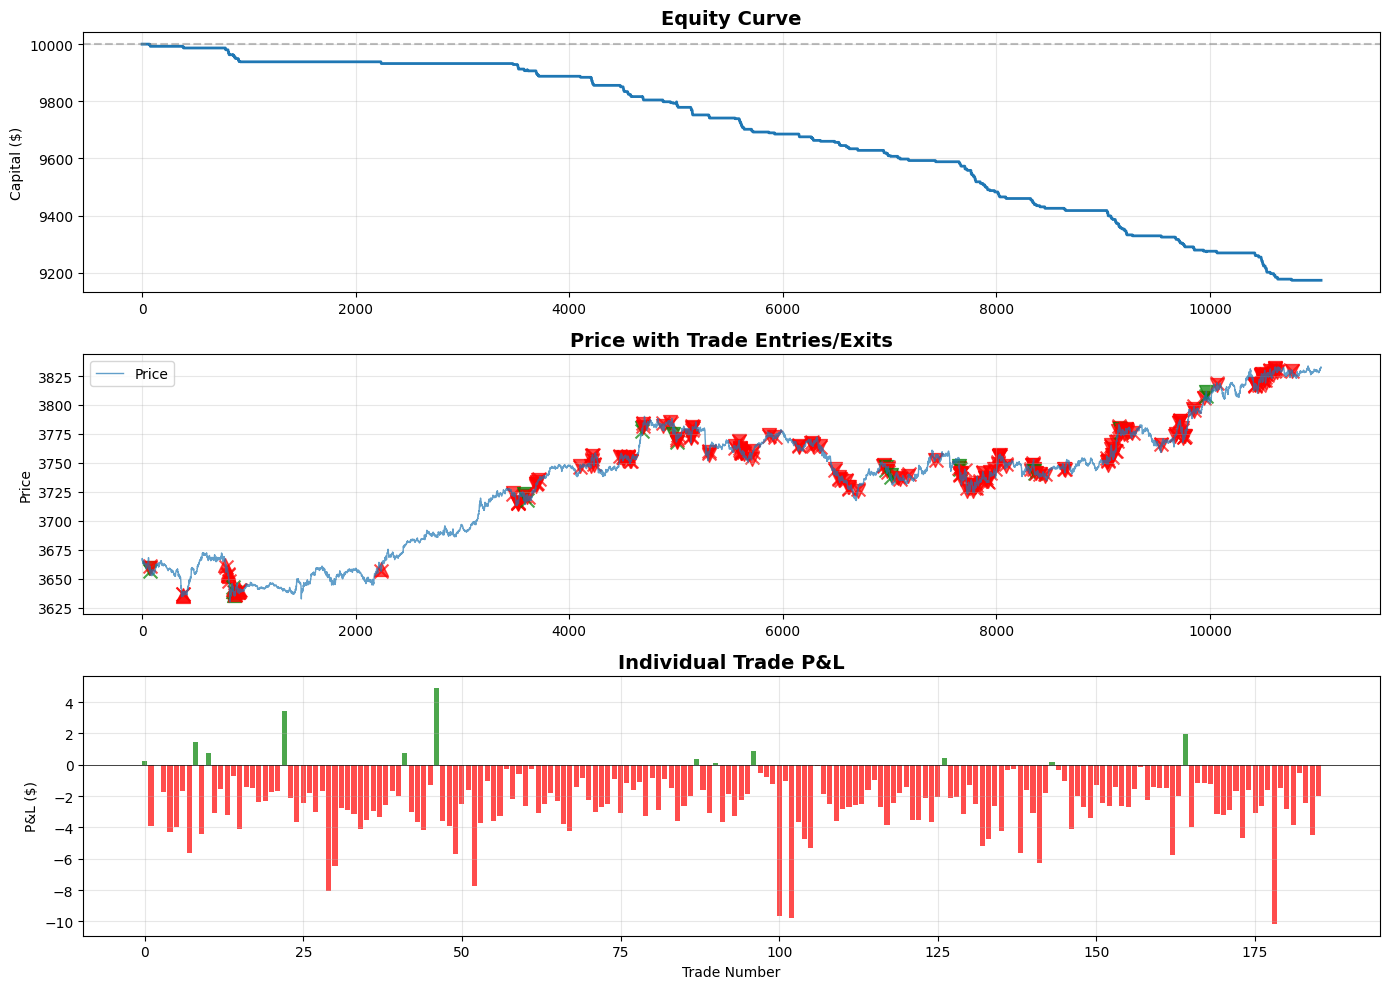

In [21]:
# ============================================================
# PROPER BACKTESTING FRAMEWORK WITH P&L CALCULATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

class TradingBacktest:
    """
    Backtest trading signals with realistic P&L calculation
    """
    
    def __init__(self, initial_capital=10000, position_size=1.0, 
                 spread=0.50, commission=0):
        """
        Parameters:
        - initial_capital: Starting capital in USD
        - position_size: Troy ounces per trade (1 oz = ~$2600 for gold)
        - spread: Bid-ask spread in USD per ounce (typical: $0.50-1.00)
        - commission: Commission per trade in USD
        """
        self.initial_capital = initial_capital
        self.position_size = position_size
        self.spread = spread
        self.commission = commission
        
    def backtest(self, df, signals, price_col='Close'):
        """
        Run backtest on historical data with signals
        
        Parameters:
        - df: DataFrame with price data
        - signals: Array of signals (1=BUY, -1=SELL, 0=HOLD/CLOSE)
        - price_col: Column name for prices
        
        Returns:
        - results: Dictionary with performance metrics
        - trades_df: DataFrame of all trades
        """
        
        df = df.copy()
        df['Signal'] = signals
        
        # Trading state
        capital = self.initial_capital
        position = 0  # 0=flat, 1=long, -1=short
        entry_price = 0
        
        # Track everything
        trades = []
        equity_curve = [capital]
        positions_history = [0]
        
        for i in range(len(df)):
            current_price = df.iloc[i][price_col]
            signal = df.iloc[i]['Signal']
            timestamp = df.iloc[i]['datetime']
            
            # Close existing position if signal changes or HOLD
            if position != 0 and (signal != position or signal == 0):
                # Calculate P&L
                if position == 1:  # Close long
                    exit_price = current_price - self.spread/2  # Pay spread
                    pnl = (exit_price - entry_price) * self.position_size
                else:  # Close short
                    exit_price = current_price + self.spread/2  # Pay spread
                    pnl = (entry_price - exit_price) * self.position_size
                
                pnl -= self.commission  # Subtract commission
                capital += pnl
                
                trades.append({
                    'entry_time': entry_time,
                    'exit_time': timestamp,
                    'direction': 'LONG' if position == 1 else 'SHORT',
                    'entry_price': entry_price,
                    'exit_price': exit_price,
                    'pnl': pnl,
                    'capital': capital
                })
                
                position = 0
            
            # Open new position
            if signal in [1, -1] and position == 0:
                position = signal
                entry_time = timestamp
                
                if signal == 1:  # Buy
                    entry_price = current_price + self.spread/2  # Pay spread
                else:  # Sell
                    entry_price = current_price - self.spread/2  # Pay spread
                
                capital -= self.commission  # Pay commission on entry
            
            equity_curve.append(capital)
            positions_history.append(position)
        
        # Close any open position at the end
        if position != 0:
            current_price = df.iloc[-1][price_col]
            if position == 1:
                exit_price = current_price - self.spread/2
                pnl = (exit_price - entry_price) * self.position_size
            else:
                exit_price = current_price + self.spread/2
                pnl = (entry_price - exit_price) * self.position_size
            
            pnl -= self.commission
            capital += pnl
            
            trades.append({
                'entry_time': entry_time,
                'exit_time': df.iloc[-1]['datetime'],
                'direction': 'LONG' if position == 1 else 'SHORT',
                'entry_price': entry_price,
                'exit_price': exit_price,
                'pnl': pnl,
                'capital': capital
            })
            
            equity_curve.append(capital)
        
        # Convert to DataFrame
        trades_df = pd.DataFrame(trades)
        
        # Calculate metrics
        results = self._calculate_metrics(trades_df, equity_curve)
        
        return results, trades_df, equity_curve
    
    def _calculate_metrics(self, trades_df, equity_curve):
        """Calculate performance metrics"""
        
        if len(trades_df) == 0:
            return {
                'total_trades': 0,
                'total_pnl': 0,
                'total_return': 0,
                'win_rate': 0,
                'avg_win': 0,
                'avg_loss': 0,
                'profit_factor': 0,
                'max_drawdown': 0,
                'sharpe_ratio': 0,
                'final_capital': self.initial_capital
            }
        
        # Basic metrics
        total_trades = len(trades_df)
        total_pnl = trades_df['pnl'].sum()
        total_return = (total_pnl / self.initial_capital) * 100
        
        # Win/Loss analysis
        winning_trades = trades_df[trades_df['pnl'] > 0]
        losing_trades = trades_df[trades_df['pnl'] <= 0]
        
        win_rate = (len(winning_trades) / total_trades * 100) if total_trades > 0 else 0
        avg_win = winning_trades['pnl'].mean() if len(winning_trades) > 0 else 0
        avg_loss = losing_trades['pnl'].mean() if len(losing_trades) > 0 else 0
        
        # Profit factor
        gross_profit = winning_trades['pnl'].sum() if len(winning_trades) > 0 else 0
        gross_loss = abs(losing_trades['pnl'].sum()) if len(losing_trades) > 0 else 0
        profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0
        
        # Max drawdown
        equity_curve = np.array(equity_curve)
        running_max = np.maximum.accumulate(equity_curve)
        drawdown = (equity_curve - running_max) / running_max * 100
        max_drawdown = abs(drawdown.min())
        
        # Sharpe ratio (annualized, assuming hourly data)
        if len(trades_df) > 1:
            returns = trades_df['pnl'] / self.initial_capital
            sharpe_ratio = (returns.mean() / returns.std()) * np.sqrt(252*24) if returns.std() > 0 else 0
        else:
            sharpe_ratio = 0
        
        return {
            'total_trades': total_trades,
            'winning_trades': len(winning_trades),
            'losing_trades': len(losing_trades),
            'total_pnl': round(total_pnl, 2),
            'total_return': round(total_return, 2),
            'win_rate': round(win_rate, 2),
            'avg_win': round(avg_win, 2),
            'avg_loss': round(avg_loss, 2),
            'profit_factor': round(profit_factor, 2),
            'max_drawdown': round(max_drawdown, 2),
            'sharpe_ratio': round(sharpe_ratio, 2),
            'final_capital': round(equity_curve[-1], 2)
        }
    
    def plot_results(self, equity_curve, trades_df, df):
        """Plot backtest results"""
        
        fig, axes = plt.subplots(3, 1, figsize=(14, 10))
        
        # 1. Equity Curve
        axes[0].plot(equity_curve, linewidth=2)
        axes[0].axhline(y=self.initial_capital, color='gray', linestyle='--', alpha=0.5)
        axes[0].set_title('Equity Curve', fontsize=14, fontweight='bold')
        axes[0].set_ylabel('Capital ($)')
        axes[0].grid(alpha=0.3)
        
        # 2. Price with Entry/Exit points
        axes[1].plot(df['Close'].values, label='Price', linewidth=1, alpha=0.7)
        
        if len(trades_df) > 0:
            # Mark entries
            for _, trade in trades_df.iterrows():
                entry_idx = df[df['datetime'] == trade['entry_time']].index[0]
                exit_idx = df[df['datetime'] == trade['exit_time']].index[0]
                
                color = 'green' if trade['pnl'] > 0 else 'red'
                marker = '^' if trade['direction'] == 'LONG' else 'v'
                
                axes[1].scatter(entry_idx, trade['entry_price'], 
                              color=color, marker=marker, s=100, alpha=0.7)
                axes[1].scatter(exit_idx, trade['exit_price'], 
                              color=color, marker='x', s=100, alpha=0.7)
        
        axes[1].set_title('Price with Trade Entries/Exits', fontsize=14, fontweight='bold')
        axes[1].set_ylabel('Price')
        axes[1].legend()
        axes[1].grid(alpha=0.3)
        
        # 3. Trade P&L
        if len(trades_df) > 0:
            colors = ['green' if pnl > 0 else 'red' for pnl in trades_df['pnl']]
            axes[2].bar(range(len(trades_df)), trades_df['pnl'], color=colors, alpha=0.7)
            axes[2].axhline(y=0, color='black', linestyle='-', linewidth=0.5)
            axes[2].set_title('Individual Trade P&L', fontsize=14, fontweight='bold')
            axes[2].set_xlabel('Trade Number')
            axes[2].set_ylabel('P&L ($)')
            axes[2].grid(alpha=0.3)
        
        plt.tight_layout()
        plt.show()

# ============================================================
# EXAMPLE: RUN BACKTEST ON YOUR MODEL
# ============================================================

print("="*70)
print("BACKTESTING YOUR ML MODEL")
print("="*70)

# Generate signals from your model on validation set
y_val_pred_proba = xgb_advanced.predict_proba(X_val_scaled)

# Use high confidence threshold (75%)
def generate_signals(proba, threshold=0.75):
    signals = []
    for p in proba:
        if p[2] >= threshold:  # Buy
            signals.append(1)
        elif p[0] >= threshold:  # Sell
            signals.append(-1)
        else:  # Hold
            signals.append(0)
    return np.array(signals)

signals = generate_signals(y_val_pred_proba, threshold=0.75)

# Initialize backtester
backtester = TradingBacktest(
    initial_capital=10000,
    position_size=1.0,  # 1 troy ounce per trade
    spread=0.50,        # $0.50 spread
    commission=2.0      # $2 commission per trade
)

# Run backtest
results, trades_df, equity_curve = backtester.backtest(
    df=val_df.reset_index(drop=True),
    signals=signals,
    price_col='Close'
)

# Print results
print("\nBACKTEST RESULTS:")
print("="*70)
print(f"Initial Capital:    ${backtester.initial_capital:,.2f}")
print(f"Final Capital:      ${results['final_capital']:,.2f}")
print(f"Total P&L:          ${results['total_pnl']:,.2f}")
print(f"Total Return:       {results['total_return']:.2f}%")
print(f"\nTotal Trades:       {results['total_trades']}")
print(f"Winning Trades:     {results['winning_trades']}")
print(f"Losing Trades:      {results['losing_trades']}")
print(f"Win Rate:           {results['win_rate']:.2f}%")
print(f"\nAverage Win:        ${results['avg_win']:.2f}")
print(f"Average Loss:       ${results['avg_loss']:.2f}")
print(f"Profit Factor:      {results['profit_factor']:.2f}")
print(f"\nMax Drawdown:       {results['max_drawdown']:.2f}%")
print(f"Sharpe Ratio:       {results['sharpe_ratio']:.2f}")
print("="*70)

# Show trades
if len(trades_df) > 0:
    print("\nFIRST 10 TRADES:")
    print(trades_df.head(10).to_string(index=False))
else:
    print("\n⚠️ WARNING: No trades generated with 75% confidence threshold")
    print("This means the model never reached 75% confidence for any signal.")
    print("Try lowering threshold to 0.60 or 0.65 to see if any trades occur.")

# Plot results
if len(trades_df) > 0:
    backtester.plot_results(equity_curve, trades_df, val_df.reset_index(drop=True))